<center><h1>You_Shihua_HW7</h1></center>

Name: Shihua You
<br>
Github Username: youshihuaaria

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

Import packages

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.metrics import balanced_accuracy_score

### (a) Download the Anuran Calls (MFCCs) Data Set

In [23]:
df = pd.read_csv("Frogs_MFCCs.csv")

labels = ["Family", "Genus", "Species"]
x = df.drop(columns=labels + ["RecordID"])
y = df[labels]

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=42)

display(df.head())
print(x_train.shape, x_test.shape)

,MFCCs_ 1,MFCCs_ 2,MFCCs_ 3,MFCCs_ 4,MFCCs_ 5,MFCCs_ 6,MFCCs_ 7,MFCCs_ 8,MFCCs_ 9,MFCCs_10,...,MFCCs_17,MFCCs_18,MFCCs_19,MFCCs_20,MFCCs_21,MFCCs_22,Family,Genus,Species,RecordID
0,1.0,0.152936,-0.105586,0.200722,0.317201,0.260764,0.100945,-0.150063,-0.171128,0.124676,...,-0.108351,-0.077623,-0.009568,0.057684,0.118680,0.014038,Leptodactylidae,Adenomera,AdenomeraAndre,1
1,1.0,0.171534,-0.098975,0.268425,0.338672,0.268353,0.060835,-0.222475,-0.207693,0.170883,...,-0.090974,-0.056510,-0.035303,0.020140,0.082263,0.029056,Leptodactylidae,Adenomera,AdenomeraAndre,1
2,1.0,0.152317,-0.082973,0.287128,0.276014,0.189867,0.008714,-0.242234,-0.219153,0.232538,...,-0.050691,-0.023590,-0.066722,-0.025083,0.099108,0.077162,Leptodactylidae,Adenomera,AdenomeraAndre,1
3,1.0,0.224392,0.118985,0.329432,0.372088,0.361005,0.015501,-0.194347,-0.098181,0.270375,...,-0.136009,-0.177037,-0.130498,-0.054766,-0.018691,0.023954,Leptodactylidae,Adenomera,AdenomeraAndre,1
4,1.0,0.087817,-0.068345,0.306967,0.330923,0.249144,0.006884,-0.265423,-0.172700,0.266434,...,-0.048885,-0.053074,-0.088550,-0.031346,0.108610,0.079244,Leptodactylidae,Adenomera,AdenomeraAndre,1


(5036, 22) (2159, 22)


### (b) Train a classifier for each label

#### (i) Research

1. Exact match is the fraction of instances for which all labels are predicted correctly. It is a strict metric, because a prediction with one wrong label counts the same as a prediction with all labels wrong.

2. Hamming loss is the fraction of labels that are predicted incorrectly over all instances and all labels. It gives credit for partially correct predictions.

3. Hamming score is the fraction of labels that are predicted correctly. Here each label takes exactly one class, so Hamming score = 1 − Hamming loss.

#### (ii) Train a SVM for each of the labels

In [24]:
def evaluate(y_true, y_pred, name):
    correct = (y_true.values == y_pred.values)

    row = {"Model": name}
    for i, label in enumerate(labels):
        row[f"{label} accuracy"] = correct[:, i].mean()
    row["Exact match"] = correct.all(axis=1).mean()
    row["Hamming score"] = correct.mean()
    row["Hamming loss"] = 1 - correct.mean()
    return row

results = []

C_values = 10.0 ** np.arange(-1, 6)
sigmas_raw = np.arange(0.1, 2.1, 0.1)
sigmas_std = np.arange(1, 10.5, 0.5)

rbf_raw = OneVsRestClassifier(SVC(kernel="rbf"))
rbf_std = Pipeline([("scaler", StandardScaler()), ("svm", OneVsRestClassifier(SVC(kernel="rbf")))])

rows = []
for name, model, prefix, sigmas in [("raw", rbf_raw, "estimator__", sigmas_raw),
                                    ("standardized", rbf_std, "svm__estimator__", sigmas_std)]:
    for C in [C_values[0], C_values[-1]]:
        for sigma in [sigmas[0], sigmas[-1]]:
            model.set_params(**{prefix + "C": C, prefix + "gamma": 1 / (2 * sigma ** 2)})
            row = {"Attributes": name, "C": C, "sigma": sigma}
            for label in labels:
                model.fit(x_train, y_train[label])
                row[label] = model.score(x_train, y_train[label])
            rows.append(row)

display(pd.DataFrame(rows).round(4))

,Attributes,C,sigma,Family,Genus,Species
0,raw,0.1,0.1,0.7583,0.7375,0.8358
1,raw,0.1,2.0,0.8805,0.8711,0.8699
2,raw,100000.0,0.1,1.0000,1.0000,1.0000
3,raw,100000.0,2.0,1.0000,1.0000,1.0000
4,standardized,0.1,1.0,0.9146,0.9110,0.9982
5,standardized,0.1,10.0,0.9206,0.8832,0.8914
6,standardized,100000.0,1.0,1.0000,1.0000,1.0000
7,standardized,100000.0,10.0,1.0000,1.0000,1.0000


In [26]:
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

def fit_labels(model, params, name):
    y_pred = pd.DataFrame(index=y_test.index, columns=labels)
    rows = []
    for label in labels:
        grid = GridSearchCV(model, params, cv=skf, scoring="accuracy", n_jobs=-1)
        grid.fit(x_train, y_train[label])
        y_pred[label] = grid.predict(x_test)

        row = {"Label": label}
        for param, value in grid.best_params_.items():
            param = param.split("__")[-1]
            row[param] = value
            if param == "gamma":
                row["sigma"] = np.sqrt(1 / (2 * value))
        row["CV accuracy"] = grid.best_score_
        row["Test accuracy"] = grid.score(x_test, y_test[label])
        rows.append(row)

    print(name)
    display(pd.DataFrame(rows).round(4))
    results.append(evaluate(y_test, y_pred, name))
    return y_pred

pred_rbf_raw = fit_labels(rbf_raw, {"estimator__C": C_values, "estimator__gamma": 1 / (2 * sigmas_raw ** 2)},
                          "Gaussian SVM (raw)")
pred_rbf_std = fit_labels(rbf_std, {"svm__estimator__C": C_values, "svm__estimator__gamma": 1 / (2 * sigmas_std ** 2)},
                          "Gaussian SVM (standardized)")

display(pd.DataFrame(results).round(4))

Gaussian SVM (raw)


,Label,C,gamma,sigma,CV accuracy,Test accuracy
0,Family,100.0,3.125,0.4,0.9927,0.9949
1,Genus,10.0,3.125,0.4,0.9919,0.9917
2,Species,10.0,3.125,0.4,0.9913,0.9907


Gaussian SVM (standardized)


,Label,C,gamma,sigma,CV accuracy,Test accuracy
0,Family,100.0,0.0556,3.0,0.9921,0.994
1,Genus,10.0,0.0556,3.0,0.9919,0.988
2,Species,10.0,0.0408,3.5,0.9911,0.988


,Model,Family accuracy,Genus accuracy,Species accuracy,Exact match,Hamming score,Hamming loss
0,Gaussian SVM (raw),0.9949,0.9917,0.9907,0.9893,0.9924,0.0076
1,Gaussian SVM (standardized),0.9940,0.9880,0.9880,0.9866,0.9900,0.0100


With C = 10 or 100, 10-fold CV chooses σ = 0.4 for the raw attributes and σ ≈ 3 for the standardized attributes. Both models are very accurate since the exact match is 0.9893 (raw) and 0.9866 (standardized), and the Hamming loss is 0.0076 and 0.0100. Standardizing does not help, because the data are already normalized.

#### (iii) Repeat 1(b)ii with L1-penalized SVMs

In [27]:
C_l1 = 10.0 ** np.arange(-3, 4)

l1_svm = Pipeline([("scaler", StandardScaler()),
                   ("svm", LinearSVC(penalty="l1", dual=False, max_iter=10000))])

pred_l1 = fit_labels(l1_svm, {"svm__C": C_l1}, "L1 SVM")
display(pd.DataFrame(results).round(4))

/opt/miniconda3/lib/python3.14/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/miniconda3/lib/python3.14/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/miniconda3/lib/python3.14/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/miniconda3/lib/python3.14/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/miniconda3/lib/python3.14/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/miniconda3/lib/python3.14/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase

L1 SVM


,Label,C,CV accuracy,Test accuracy
0,Family,10.0,0.9412,0.9282
1,Genus,1000.0,0.9517,0.9416
2,Species,10.0,0.9607,0.9592


,Model,Family accuracy,Genus accuracy,Species accuracy,Exact match,Hamming score,Hamming loss
0,Gaussian SVM (raw),0.9949,0.9917,0.9907,0.9893,0.9924,0.0076
1,Gaussian SVM (standardized),0.9940,0.9880,0.9880,0.9866,0.9900,0.0100
2,L1 SVM,0.9282,0.9416,0.9592,0.9125,0.9430,0.0570


CV chooses C = 10 for Family and Species and C = 1000 for Genus, but the CV accuracy is almost flat for C ≥ 1. The exact match is 0.9125 and the Hamming loss is 0.0570, worse than the Gaussian SVM. The classes are not linearly separable, so the Gaussian kernel fits this data much better.

#### (iv) Repeat 1(b)iii by using SMOTE or any other method for imbalance

In [28]:
smote_svm = ImbPipeline([("scaler", StandardScaler()),
                         ("smote", SMOTE(random_state=42)),
                         ("svm", LinearSVC(penalty="l1", dual=False, max_iter=10000))])

pred_smote = fit_labels(smote_svm, {"svm__C": C_l1}, "L1 SVM + SMOTE")

display(pd.DataFrame(results).round(4))

rows = []
for label in labels:
    rows.append({
        "Label": label,
        "L1 SVM": balanced_accuracy_score(y_test[label], pred_l1[label]),
        "L1 SVM + SMOTE": balanced_accuracy_score(y_test[label], pred_smote[label]),
    })

display(pd.DataFrame(rows).round(4))

/opt/miniconda3/lib/python3.14/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
/opt/miniconda3/lib/python3.14/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/miniconda3/lib/python3.14/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/miniconda3/lib/python3.14/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


L1 SVM + SMOTE


,Label,C,CV accuracy,Test accuracy
0,Family,10.0,0.9232,0.9092
1,Genus,1.0,0.9128,0.9023
2,Species,10.0,0.9581,0.9579


,Model,Family accuracy,Genus accuracy,Species accuracy,Exact match,Hamming score,Hamming loss
0,Gaussian SVM (raw),0.9949,0.9917,0.9907,0.9893,0.9924,0.0076
1,Gaussian SVM (standardized),0.9940,0.9880,0.9880,0.9866,0.9900,0.0100
2,L1 SVM,0.9282,0.9416,0.9592,0.9125,0.9430,0.0570
3,L1 SVM + SMOTE,0.9092,0.9023,0.9579,0.8536,0.9231,0.0769


,Label,L1 SVM,L1 SVM + SMOTE
0,Family,0.6902,0.9131
1,Genus,0.7690,0.9162
2,Species,0.8948,0.9278


With SMOTE, the exact match drops from 0.9125 to 0.8536, but the balanced accuracy improves for every label. Without SMOTE, the L1 SVM misclassifies every test instance of the smallest family, Bufonidae.

So the Gaussian SVM is the best classifier, with an exact match of about 0.99. The L1-penalized linear SVMs are worse because the classes are not linearly separable. SMOTE lowers the overall accuracy but gives much better recall on the minority classes.

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

### (a) Use k-means clustering

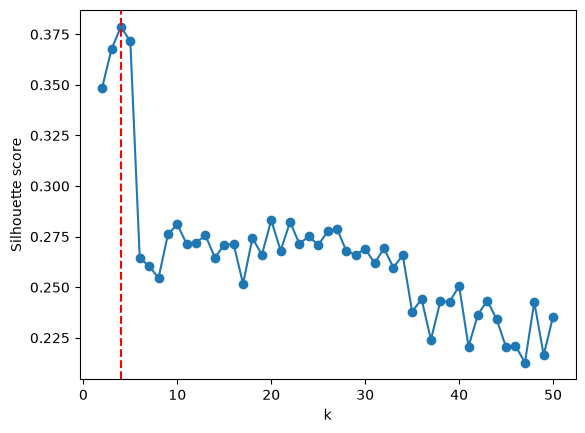

Best k: 4
Silhouette score: 0.3788


In [29]:
k_values = range(2, 51)

def best_kmeans(seed):
    best_score, best_model, scores = -1, None, []
    for k in k_values:
        kmeans = KMeans(n_clusters=k, n_init=10, random_state=seed)
        kmeans.fit(x)
        score = silhouette_score(x, kmeans.labels_)
        scores.append(score)
        if score > best_score:
            best_score, best_model = score, kmeans
    return best_model, scores

kmeans, scores = best_kmeans(0)
best_k = kmeans.n_clusters

plt.plot(k_values, scores, marker="o")
plt.axvline(best_k, color="red", linestyle="--")
plt.xlabel("k")
plt.ylabel("Silhouette score")
plt.show()

print("Best k:", best_k)
print("Silhouette score:", round(max(scores), 4))

For this run the best value is k = 4, with a silhouette score of 0.3788. The score drops sharply after k = 5 and stays lower for larger k.

### (b) Determine which family is the majority

In [30]:
def majority_labels(clusters):
    return y.groupby(clusters).agg(lambda s: s.value_counts().idxmax())

majority = majority_labels(kmeans.labels_)
majority.index.name = "Cluster"
majority["Size"] = pd.Series(kmeans.labels_).value_counts().sort_index()

display(majority)

,Family,Genus,Species,Size
Cluster,,,,
0,Leptodactylidae,Adenomera,AdenomeraHylaedactylus,3568
1,Hylidae,Hypsiboas,HypsiboasCordobae,1982
2,Dendrobatidae,Ameerega,Ameeregatrivittata,1031
3,Hylidae,Hypsiboas,HypsiboasCinerascens,614


With k = 4, the clusters can only cover 3 of the 4 families, 3 of the 8 genera, and 4 of the 10 species. Two clusters have the same majority family and genus (Hylidae, Hypsiboas) but different species. The small classes, such as Bufonidae, are never a majority, so all of their instances are assigned a wrong label.

### (c) Calculate the average Hamming distance, Hamming score, and Hamming loss

In [31]:
def hamming(clusters):
    y_pred = majority_labels(clusters).loc[clusters]
    wrong = (y.values != y_pred.values)

    distance = wrong.sum(axis=1).mean()
    loss = wrong.mean()
    return distance, 1 - loss, loss

distance, score, loss = hamming(kmeans.labels_)
print("Hamming distance:", round(distance, 4))
print("Hamming score:", round(score, 4))
print("Hamming loss:", round(loss, 4))

rows = []
for seed in range(50):
    kmeans_mc, _ = best_kmeans(seed)
    distance, score, loss = hamming(kmeans_mc.labels_)
    rows.append({"k": kmeans_mc.n_clusters, "Hamming distance": distance,
                 "Hamming score": score, "Hamming loss": loss})

mc = pd.DataFrame(rows)
display(mc.round(4))
display(mc.agg(["mean", "std"]).round(4))

Hamming distance: 0.6673
Hamming score: 0.7776
Hamming loss: 0.2224


,k,Hamming distance,Hamming score,Hamming loss
0,4,0.6673,0.7776,0.2224
1,4,0.6673,0.7776,0.2224
2,4,0.7354,0.7549,0.2451
3,4,0.6673,0.7776,0.2224
4,4,0.6673,0.7776,0.2224
5,4,0.6673,0.7776,0.2224
6,4,0.6673,0.7776,0.2224
7,4,0.6673,0.7776,0.2224
8,4,0.6673,0.7776,0.2224
9,4,0.6673,0.7776,0.2224


,k,Hamming distance,Hamming score,Hamming loss
mean,4.0,0.6719,0.7760,0.2240
std,0.0,0.0170,0.0057,0.0057


Over the 50 Monte-Carlo runs, the silhouette method chooses k = 4 every time. The average Hamming distance is 0.6719 with a standard deviation of 0.0170, the average Hamming score is 0.7760 (std 0.0057), and the average Hamming loss is 0.2240 (std 0.0057). 

## 3. ISLR 12.6.2

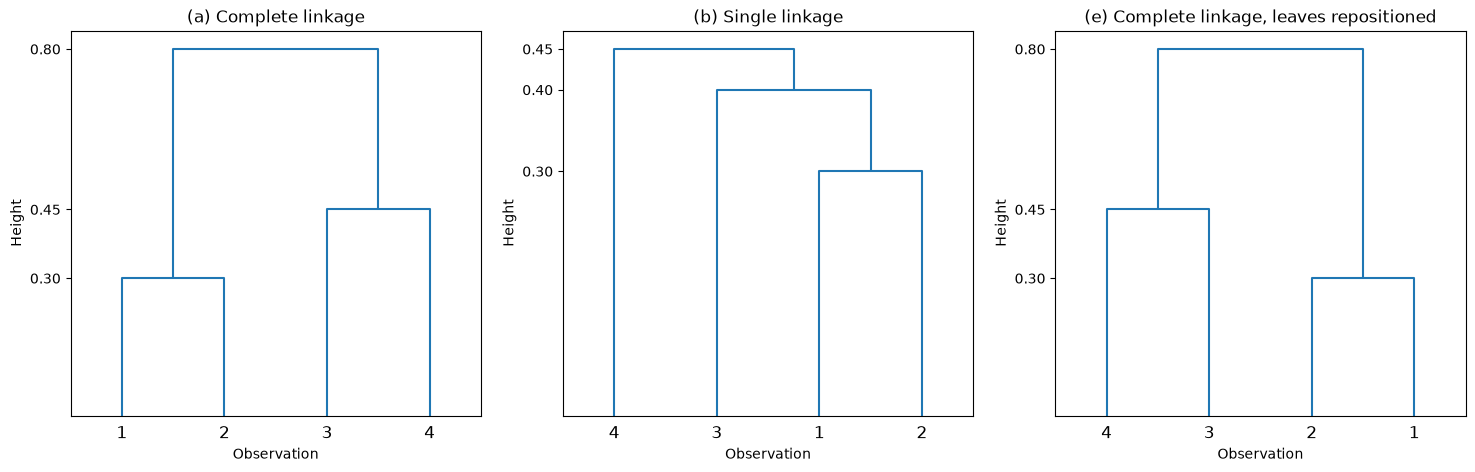

In [32]:
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform

d = np.array([[0, 0.3, 0.4, 0.7],
              [0.3, 0, 0.5, 0.8],
              [0.4, 0.5, 0, 0.45],
              [0.7, 0.8, 0.45, 0]])
obs = ["1", "2", "3", "4"]

z_complete = linkage(squareform(d), method="complete")
z_single = linkage(squareform(d), method="single")
z_swapped = z_complete[:, [1, 0, 2, 3]]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
titles = ["(a) Complete linkage", "(b) Single linkage", "(e) Complete linkage, leaves repositioned"]

for ax, z, title in zip(axes, [z_complete, z_single, z_swapped], titles):
    dendrogram(z, labels=obs, ax=ax, color_threshold=0)
    ax.set_yticks(sorted(z[:, 2]))
    ax.set_title(title)
    ax.set_xlabel("Observation")
    ax.set_ylabel("Height")

plt.show()

### (a)

1. The smallest dissimilarity is 0.3, so observations 1 and 2 are fused at height 0.3.
2. Now $d(\{1,2\}, 3) = \max(0.4, 0.5) = 0.5$, $d(\{1,2\}, 4) = \max(0.7, 0.8) = 0.8$, and $d(3, 4) = 0.45$. The smallest is 0.45, so observations 3 and 4 are fused at height 0.45.
3. Finally, $d(\{1,2\}, \{3,4\}) = \max(0.4, 0.7, 0.5, 0.8) = 0.8$, so {1, 2} and {3, 4} are fused at height 0.8.

### (b)

1. Observations 1 and 2 are fused at height 0.3.
2. Now $d(\{1,2\}, 3) = \min(0.4, 0.5) = 0.4$, $d(\{1,2\}, 4) = \min(0.7, 0.8) = 0.7$, and $d(3, 4) = 0.45$. The smallest is 0.4, so {1, 2} and 3 are fused at height 0.4.
3. Finally, $d(\{1,2,3\}, 4) = \min(0.7, 0.8, 0.45) = 0.45$, so {1, 2, 3} and 4 are fused at height 0.45.

### (c)

Cutting the dendrogram in (a) between heights 0.45 and 0.8 gives two clusters: {1, 2} and {3, 4}.

### (d)

Cutting the dendrogram in (b) between heights 0.4 and 0.45 gives two clusters: {1, 2, 3} and {4}.

### (e)

The third plot swaps the two branches at every fusion of the dendrogram in (a), so the leaves are in the order 4, 3, 2, 1. The fusions and their heights are the same (1 and 2 at 0.3, 3 and 4 at 0.45, and the two clusters at 0.8), so the meaning of the dendrogram is the same.